# 01 · Clasificación de equipos por color de camiseta

**Objetivo:** asignar cada jugador a su equipo mediante el color dominante de la camiseta, agrupando con K-means (k=2) los colores medios de cada track.

**Contexto:** el tracking proporciona identidades, pero no distingue equipos. Para cada detección se recorta la zona del torso, se eliminan los píxeles de césped (filtro HSV) y se calcula el color medio. El color de cada track se promedia sobre todas sus apariciones, lo que hace la clasificación robusta a frames individuales malos. Los porteros, con equipación distinta, aparecerán como outliers de los clusters.

**Entrada:** vídeo y salida estructurada del tracking (`data/tracking/`).

**Salida:** asignación track → equipo y vídeo de validación con colores de equipo.

In [2]:
import json
import cv2
import numpy as np
from pathlib import Path
from collections import defaultdict

REPO_ROOT = Path("../..").resolve()
VIDEO_IN = REPO_ROOT / "data" / "raw" / "A1606b0e6_0 (62).mp4"
TRACKING_JSON = REPO_ROOT / "data" / "tracking" / "tracking_A1606b0e6_62.json"

with open(TRACKING_JSON) as f:
    tracking = json.load(f)
frames_track = tracking["frames"]

print(f"Vídeo existe: {VIDEO_IN.exists()}")
print(f"Frames de tracking: {len(frames_track)}")

Vídeo existe: True
Frames de tracking: 749


## 1. Extracción del color de la equipación

Para cada detección de jugador se recorta la zona del torso (22%-50% vertical, 50% central horizontal, evitando piernas y brazos), se eliminan los píxeles de césped (filtro HSV de verdes) y se extrae el color dominante con un mini K-means: el cluster mayoritario corresponde a la camiseta. Se guarda junto con la altura de la caja como peso de fiabilidad.

In [3]:
def color_camiseta(frame, bbox):
    """Color DOMINANTE del torso (BGR) por mini K-means sobre píxeles sin césped."""
    x1, y1, x2, y2 = [int(v) for v in bbox]
    h_box = y2 - y1
    w_box = x2 - x1
    if h_box < 10 or w_box < 4:
        return None
    ty1 = y1 + int(0.22 * h_box)
    ty2 = y1 + int(0.50 * h_box)
    tx1 = x1 + int(0.25 * w_box)
    tx2 = x2 - int(0.25 * w_box)
    crop = frame[max(ty1, 0):ty2, max(tx1, 0):tx2]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    verde = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255))
    pix = crop[verde == 0].astype(np.float32)
    if len(pix) < 30:
        return None
    if len(pix) > 300:
        idx = np.random.default_rng(0).choice(len(pix), 300, replace=False)
        pix = pix[idx]
    k = 3 if len(pix) >= 60 else 1
    if k == 1:
        return pix.mean(axis=0)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    _, labels, centers = cv2.kmeans(pix, k, None, criteria, 3, cv2.KMEANS_PP_CENTERS)
    return centers[np.bincount(labels.ravel()).argmax()]

# Recorrer el vídeo guardando (frame, color, peso) por track
colores_track = defaultdict(list)   # id -> lista de (f_idx, BGR, peso)

cap = cv2.VideoCapture(str(VIDEO_IN))
for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break
    for d in dets:
        if d["cls"] != 1:
            continue
        c = color_camiseta(frame, d["bbox"])
        if c is not None:
            h_box = d["bbox"][3] - d["bbox"][1]
            colores_track[d["id"]].append((f_idx, c, h_box))
cap.release()

print(f"Tracks con colores: {len(colores_track)}")
print(f"Detecciones con color: {sum(len(v) for v in colores_track.values())}")

Tracks con colores: 34
Detecciones con color: 14974


Figura guardada en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\colores_tracks.png


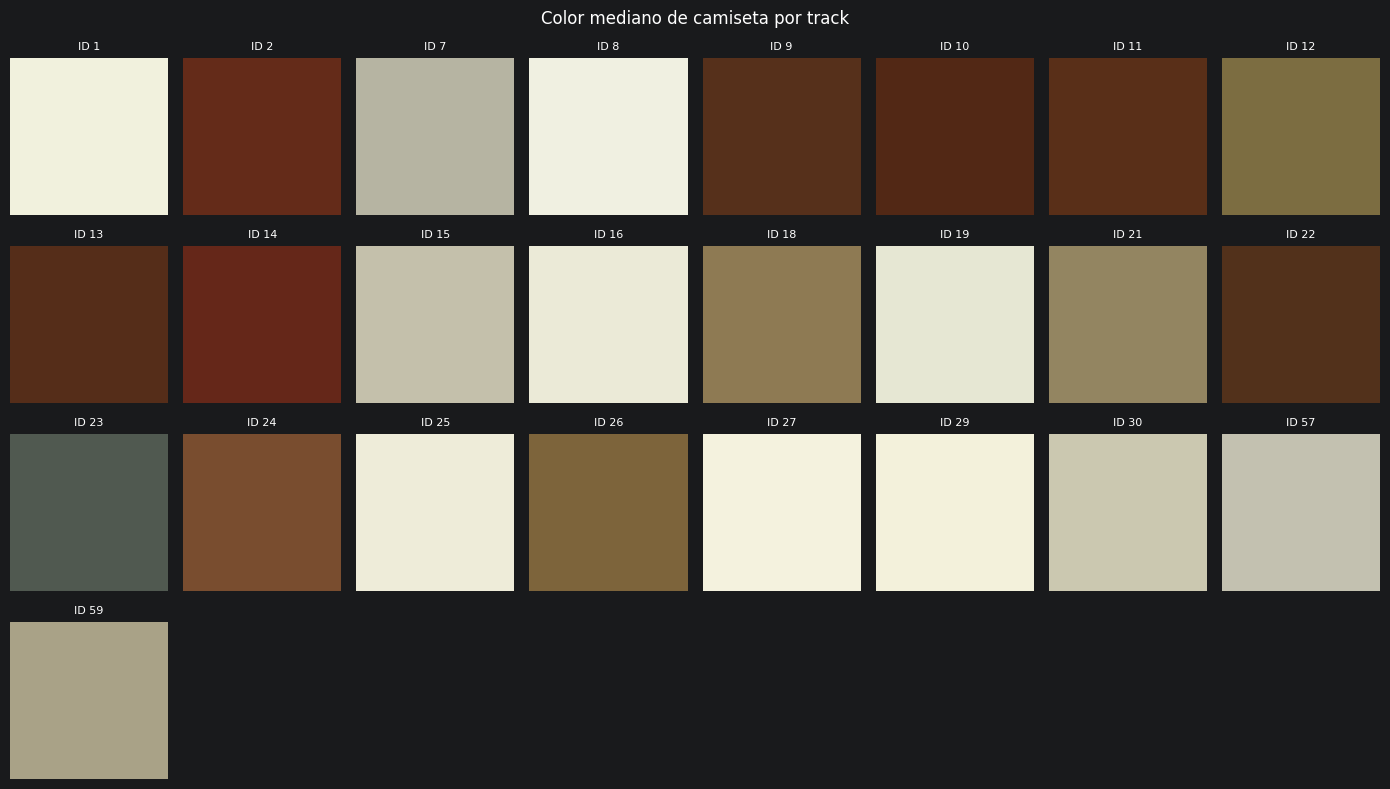

In [4]:
# Validación visual: color mediano extraído de cada track
%matplotlib inline
import matplotlib.pyplot as plt

medianas = {tid: np.median(np.array([c for f, c, p in v]), axis=0)
            for tid, v in colores_track.items() if len(v) >= 5}

tids_vis = sorted(medianas.keys())
n = len(tids_vis)
cols = 8
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, 2 * rows))
for ax in np.ravel(axes):
    ax.axis("off")
for ax, tid in zip(np.ravel(axes), tids_vis):
    b, g, r = medianas[tid] / 255.0
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color=(r, g, b)))
    ax.set_title(f"ID {tid}", fontsize=8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

plt.suptitle("Color mediano de camiseta por track")
plt.tight_layout()
output_fig = REPO_ROOT / "outputs" / "colores_tracks.png"
plt.savefig(str(output_fig), dpi=100, bbox_inches="tight")
print(f"Figura guardada en: {output_fig}")
plt.show()

## 2. Clasificación por voto ponderado en espacio Lab

Los centroides de los dos equipos se aprenden con K-means (k=2) usando solo las detecciones con caja grande (color fiable), en los canales a,b de Lab. Cada track se asigna al equipo por el que vota la mayoría ponderada de sus detecciones: así un jugador que pasa parte del clip lejos (color contaminado hacia el caqui por el desenfoque con el césped) se clasifica correctamente por sus frames cercanos. Los tracks lejos de ambos centroides se marcan como outliers (porteros).

In [5]:
# Clasificación v5: equipo por detección (modelo equipación-césped) + división de
# tracks por cambio sostenido de equipo (corrige swaps inter-equipo del tracking)
def bgr_a_ab(colores_bgr):
    img = np.clip(np.array(colores_bgr), 0, 255).astype(np.uint8).reshape(-1, 1, 3)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2Lab).reshape(-1, 3).astype(np.float32)
    return lab[:, 1:3]

# ---- 0. Color del césped ----
cap = cv2.VideoCapture(str(VIDEO_IN))
total_f = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
muestras = []
for fi in range(0, total_f, 150):
    cap.set(cv2.CAP_PROP_POS_FRAMES, fi)
    ret, fr = cap.read()
    if not ret:
        continue
    hsv = cv2.cvtColor(fr, cv2.COLOR_BGR2HSV)
    masc = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)) > 0
    pix = fr[masc]
    if len(pix) > 1000:
        idx = np.random.default_rng(0).choice(len(pix), 1000, replace=False)
        muestras.append(pix[idx])
cap.release()
cesped_bgr = np.median(np.vstack(muestras).astype(float), axis=0)
ab_cesped = bgr_a_ab([cesped_bgr])[0]

# ---- 1. Aplanar detecciones (con frame) ----
det_frames, det_colors, det_pesos, det_tids = [], [], [], []
for tid, lst in colores_track.items():
    for (f, c, p) in lst:
        det_frames.append(f)
        det_colors.append(c)
        det_pesos.append(p)
        det_tids.append(int(tid))
det_frames = np.array(det_frames)
det_ab = bgr_a_ab(det_colors)
det_pesos = np.array(det_pesos)
det_tids = np.array(det_tids)

dist_cesped = np.linalg.norm(det_ab - ab_cesped, axis=1)
D_INFORMATIVA = 12.0
informativas = dist_cesped >= D_INFORMATIVA

# ---- 2. Equipaciones (k=2 con detecciones cercanas e informativas) ----
H_KIT = 60
base = informativas & (det_pesos >= H_KIT)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-4)
_, _, kits = cv2.kmeans(det_ab[base], 2, None, criteria, 20, cv2.KMEANS_PP_CENTERS)
print(f"Equipación 0 (ab): {kits[0]}, Equipación 1 (ab): {kits[1]}")

# ---- 3. Etiqueta de equipo por detección (segmento equipación-césped) ----
def dist_a_segmento(P, a, b):
    ab_v = b - a
    t = np.clip(((P - a) @ ab_v) / (ab_v @ ab_v + 1e-9), 0, 1)
    proy = a + t[:, None] * ab_v
    return np.linalg.norm(P - proy, axis=1)

d0 = dist_a_segmento(det_ab, kits[0], ab_cesped)
d1 = dist_a_segmento(det_ab, kits[1], ab_cesped)
det_lab = np.where(d0 < d1, 0, 1)
det_lab = np.where(informativas, det_lab, -9)   # -9 = sin información (césped puro)

# ---- 4. División de tracks por cambio SOSTENIDO de equipo (histéresis) ----
MIN_CAMBIO = 20   # detecciones informativas seguidas del otro equipo para partir

equipo_det = {}     # (frame, tid_original) -> equipo del segmento
id_final_det = {}   # (frame, tid_original) -> id tras división
segmentos_info = []
n_partidos = 0

for tid in sorted(colores_track.keys()):
    m = det_tids == int(tid)
    orden = np.argsort(det_frames[m])
    fs = det_frames[m][orden]
    labs = det_lab[m][orden]
    pesos = det_pesos[m][orden]

    segs = []           # lista de listas de índices (sobre fs/labs)
    actual = []
    pendiente = []
    eq_actual = None
    for i in range(len(fs)):
        l = labs[i]
        if l == -9:
            (pendiente if pendiente else actual).append(i)
            continue
        if eq_actual is None:
            eq_actual = l
        if l == eq_actual:
            if pendiente:
                actual.extend(pendiente)
                pendiente = []
            actual.append(i)
        else:
            pendiente.append(i)
            n_otro = sum(1 for j in pendiente if labs[j] == l)
            if n_otro >= MIN_CAMBIO:
                if actual:
                    segs.append((eq_actual, actual))
                eq_actual = l
                actual = pendiente
                pendiente = []
    if pendiente:
        actual.extend(pendiente)
    if actual:
        segs.append((eq_actual, actual))
    if len(segs) > 1:
        n_partidos += 1

    for s_idx, (eq_seg, idxs) in enumerate(segs):
        nid = int(tid) if s_idx == 0 else int(tid) * 1000 + s_idx
        # Equipo del segmento por mayoría ponderada de sus informativas
        inf = [i for i in idxs if labs[i] != -9]
        if len(inf) < 5:
            eq = -1
        else:
            v0 = sum(pesos[i] for i in inf if labs[i] == 0)
            v1 = sum(pesos[i] for i in inf if labs[i] == 1)
            eq = 0 if v0 > v1 else 1
        segmentos_info.append((nid, eq, int(fs[idxs[0]]), int(fs[idxs[-1]]), len(idxs)))
        for i in idxs:
            equipo_det[(int(fs[i]), int(tid))] = eq
            id_final_det[(int(fs[i]), int(tid))] = nid

print(f"Tracks partidos por cambio de equipo: {n_partidos}")

# ---- 5. Colores representativos y resumen ----
def realzar(c):
    c = np.array(c, dtype=float)
    return tuple(int(v) for v in (c / (c.max() + 1e-6) * 255))

det_colors_arr = np.array(det_colors)
color_equipo_bgr = {}
for eq in (0, 1):
    sel = base & (det_lab == eq)
    color_equipo_bgr[eq] = realzar(det_colors_arr[sel].mean(axis=0)) if sel.sum() else (128, 128, 128)

nombres = {0: "Equipo A", 1: "Equipo B", -1: "OUTLIER"}
print(f"\n{'Segmento':>9} {'Equipo':>9} {'F.ini':>6} {'F.fin':>6} {'NDets':>6}")
for (nid, eq, f0, f1, nd) in segmentos_info:
    print(f"{nid:>9} {nombres[eq]:>9} {f0:>6} {f1:>6} {nd:>6}")

n_a = len({s[0] for s in segmentos_info if s[1] == 0})
n_b = len({s[0] for s in segmentos_info if s[1] == 1})
n_out = len({s[0] for s in segmentos_info if s[1] == -1})
print(f"\nSegmentos Equipo A: {n_a}, Equipo B: {n_b}, Outliers: {n_out}")

Equipación 0 (ab): [125.54678 139.90582], Equipación 1 (ab): [144.63391 150.50882]
Tracks partidos por cambio de equipo: 5

 Segmento    Equipo  F.ini  F.fin  NDets
        1  Equipo A      0    748    748
        2  Equipo B      0    748    713
        7  Equipo A      0    748    746
        8  Equipo A      0    748    749
        9  Equipo B      0    748    746
       10  Equipo B      0    748    756
       11  Equipo B      0    748    749
       12  Equipo B    252    680      5
       13  Equipo B      0    748    749
       14  Equipo B      0    748    749
       15  Equipo A      0    748    749
       16  Equipo A      0    748    747
       18  Equipo A      0    358    358
    18001  Equipo B    359    748    389
       19  Equipo B      0    116    115
    19001  Equipo A    117    748    596
       21  Equipo B      0    358    354
    21001  Equipo A    359    748    390
       22  Equipo B      0    748    743
       23  Equipo A      0    172    139
       24  Equi

In [6]:
# Vídeo de validación: equipo por detección/segmento
OUTPUT_EQ = REPO_ROOT / "outputs" / "equipos_validacion_v7.mp4"

COLOR_OUTLIER = (255, 0, 255)
COLOR_ARBITRO = (0, 0, 0)
COLOR_BALON = (0, 255, 255)

cap = cv2.VideoCapture(str(VIDEO_IN))
fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(str(OUTPUT_EQ), fourcc, fps, (w, h))

for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break
    for d in dets:
        x1, y1, x2, y2 = [int(v) for v in d["bbox"]]
        if d["cls"] == 1:
            eq = equipo_det.get((f_idx, d["id"]))
            nid = id_final_det.get((f_idx, d["id"]), d["id"])
            if eq is None:
                color = (128, 128, 128)
            elif eq == -1:
                color = COLOR_OUTLIER
            else:
                color = color_equipo_bgr[eq]
            cv2.putText(frame, f"{nid}", (x1, y1 - 5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        elif d["cls"] == 2:
            color = COLOR_ARBITRO
        else:
            color = COLOR_BALON
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
    writer.write(frame)

cap.release()
writer.release()
print(f"Vídeo guardado en: {OUTPUT_EQ}")

Vídeo guardado en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\equipos_validacion_v7.mp4


In [7]:
# Exportar tracking + equipos por frame (interfaz para la fase 5)
out_final = REPO_ROOT / "data" / "tracking" / "tracking_equipos_A1606b0e6_62.json"
salida = []
for f_idx, dets in enumerate(frames_track):
    fr = []
    for d in dets:
        eq = equipo_det.get((f_idx, d["id"])) if d["cls"] == 1 else None
        nid = id_final_det.get((f_idx, d["id"]), d["id"]) if d["cls"] == 1 else d["id"]
        fr.append({"id": int(nid), "bbox": d["bbox"], "cls": d["cls"],
                   "equipo": (int(eq) if eq is not None else None)})
    salida.append(fr)

with open(out_final, "w") as f:
    json.dump({"video": VIDEO_IN.name,
               "color_equipo_bgr": {str(k): [int(x) for x in v] for k, v in color_equipo_bgr.items()},
               "frames": salida}, f)
print(f"Exportado: {out_final}")

Exportado: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\tracking\tracking_equipos_A1606b0e6_62.json


## Iteraciones descartadas (registro)

El método final es el resultado de tres iteraciones, que se documentan a continuación (código comentado, no forma parte del pipeline):

**Iteración 1 — Color medio del torso:** la media de los píxeles sin césped mezclaba camiseta, piel y sombras: el rojo aparecía como marrón y el blanco como beige. Funcionaba la separación pero los colores eran poco fieles.

**Iteración 2 — Mediana + K-means sobre cromaticidad RGB de las medianas por track:** la mediana mejoró la robustez a frames contaminados, pero los jugadores lejanos (cuyo color se funde con el césped hacia el caqui por el desenfoque) se agrupaban con el equipo claro, desequilibrando los clusters (16 vs 7) y generando falsos outliers.

**Iteración 3 (final) — Color dominante + Lab + voto ponderado:** descrita en la cabecera del notebook. Resuelve la piel (cluster minoritario descartado) y la distancia (los centroides se aprenden de cajas grandes y cada track vota con el peso de sus frames fiables).

In [ ]:
# =====================================================================
# ITERACIONES DESCARTADAS (ver Markdown anterior). NO ejecutar.
# =====================================================================

# --- Iteración 1: color medio del torso (mezclaba piel y sombras) ---
# def color_camiseta_v1(frame, bbox):
#     x1, y1, x2, y2 = [int(v) for v in bbox]
#     h_box = y2 - y1
#     w_box = x2 - x1
#     if h_box < 10 or w_box < 4:
#         return None
#     ty1 = y1 + int(0.20 * h_box)
#     ty2 = y1 + int(0.55 * h_box)
#     tx1 = x1 + int(0.20 * w_box)
#     tx2 = x2 - int(0.20 * w_box)
#     crop = frame[max(ty1, 0):ty2, max(tx1, 0):tx2]
#     if crop.size == 0:
#         return None
#     hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
#     verde = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255))
#     validos = crop[verde == 0]
#     if len(validos) < 20:
#         return None
#     return validos.mean(axis=0)

# --- Iteración 2: K-means k=2 sobre cromaticidad RGB de las medianas por track ---
# (desequilibraba los clusters por los jugadores lejanos color caqui)
# tids = sorted(medianas.keys())
# feats = []
# for tid in tids:
#     b, g, r = medianas[tid]
#     s = b + g + r + 1e-6
#     feats.append([r / s, g / s])
# feats = np.array(feats, dtype=np.float32)
# criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-4)
# _, etiquetas, centros = cv2.kmeans(feats, 2, None, criteria, 20, cv2.KMEANS_PP_CENTERS)
# etiquetas = etiquetas.ravel()
# dists = np.linalg.norm(feats - centros[etiquetas], axis=1)
# umbral = 4.0 * np.median(dists)
# equipo_de = {tid: (int(lab) if d <= umbral else -1)
#              for tid, lab, d in zip(tids, etiquetas, dists)}

print("Celda de iteraciones descartadas: no ejecuta nada (código comentado)")